# Rician Fading Testbench — Batched Flat-Plane Scenario

Sweep scattering parameter **S** over a flat concrete ground plane.
For each S value, **N_REALIZATIONS** small-scale realisations are run in
batches of **BATCH_SIZE** receivers per solver call.

| Output variable | Description |
|---|---|
| `raw_results[s_idx]` | List of dicts: `taus`, `amps`, `inter_d0`, `rx_pos` per realisation |
| `Hs[s_idx]` | Composite envelope \|h\| per realisation |
| `powers[s_idx]` | `(P_LoS, P_scat)` tuples per realisation |
| `tau_rms_all[s_idx]` | RMS delay spread [s] per realisation |
| `p_los_all[s_idx]` | LoS indicator (0 or 1) per realisation |

Raw data enables per-realisation CIR plots and comparison across S values.

## 1 · Environment Setup

In [1]:
import os
os.environ['DRJIT_LIBLLVM_PATH'] = '/usr/lib/x86_64-linux-gnu/libLLVM-20.so'
# os.environ["CUDA_VISIBLE_DEVICES"] = "1"
import drjit as drjit

%env DRJIT_LIBLLVM_PATH="/usr/lib/x86_64-linux-gnu/libLLVM-20.so"

env: DRJIT_LIBLLVM_PATH="/usr/lib/x86_64-linux-gnu/libLLVM-20.so"


## 2 · Imports

In [2]:
import numpy as np
import tensorflow as tf

import sionna
# Import or install Sionna
try:
    import sionna.rt
except ImportError as e:
    import os
    os.system("pip install sionna-rt")
    import sionna.rt

# Other imports
%matplotlib inline
import matplotlib.pyplot as plt
import matplotlib as mpl
import numpy as np
from scipy import constants

no_preview = False # Toggle to False to use the preview widget
import mitsuba as mi
# mi.set_variant("cuda_rgb")
# Import relevant components from Sionna RT
from sionna.rt import load_scene, PlanarArray, Transmitter, Receiver, Camera,\
                      PathSolver, RadioMapSolver, subcarrier_frequencies, LambertianPattern

import gc
import pickle
import time
import math

2026-04-10 08:48:49.847083: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [3]:
from scipy.special import i0e

## 3 · Configuration

> **Edit this cell** before running to set the sweep parameters.

In [4]:
# ─── Scene ────────────────────────────────────────────────────────────────────
SCENE_XML    = "./flat_plane/plain.xml"   # flat concrete ground plane

# ─── RF ───────────────────────────────────────────────────────────────────────
FREQUENCY    = 11.7e9   # Carrier frequency [Hz]
TX_POWER_DBM = 43       # Transmit power [dBm]

# ─── Geometry ─────────────────────────────────────────────────────────────────
TX_POS       = [100, 0, 10]    # Transmitter position [m]
RX_NOM       = [0.0, 0.0, 0.5] # Nominal receiver position [m]

LAMBDA_C     = 3e8 / FREQUENCY         # Carrier wavelength [m]
PERTURB_HALF = LAMBDA_C          # ±λ perturbation half-width [m]
BEAM_ANGLE   = np.arctan(50 / np.linalg.norm(TX_POS))  # cone half-angle [rad]

# ─── S sweep ──────────────────────────────────────────────────────────────────
S_VALUES     = [0.3, 0.7, 1.0]   # Scattering coefficients to sweep

# ─── Simulation budget ────────────────────────────────────────────────────────
N_REALIZATIONS       = 10_000    # Realisations per S value
BATCH_SIZE           = 1       # Receivers per solver call
BASE_SAMPLES_PER_SRC = 1_000_000  # Scaled up by actual batch size
BASE_MAX_PATHS       = 1_000_000  # Scaled up by actual batch size

# ─── Material properties ────────────────────────────────────────────────────────
# Concrete material properties (ITU-R P.2040-1)
a = 5.24; b = 0.0; c = 0.0462; d = 0.7822
SCATTERING_COEFF = 0.4  # Scattering
eta_r = a*(FREQUENCY/1e9)**b          # Relative permittivity (dielectric constant)
sigma = c*(FREQUENCY/1e9)**d       # Conductivity [S/m]

# ─── I/O ──────────────────────────────────────────────────────────────────────
RESULTS_FILE    = "rician_testbench_batched.pkl"
CHECKPOINT_FILE = "rician_testbench_checkpoint.pkl"
RNG_SEED        = 42

N_BATCHES = math.ceil(N_REALIZATIONS / BATCH_SIZE)

print(f"S values       : {S_VALUES}")
print(f"N_REALIZATIONS : {N_REALIZATIONS}  per S value")
print(f"BATCH_SIZE     : {BATCH_SIZE}  receivers per solver call")
print(f"N_BATCHES      : {N_BATCHES}  per S value")
print(f"lambda_c       : {LAMBDA_C*1e3:.2f} mm")
print(f"Perturbation   : +-{PERTURB_HALF*1e3:.1f} mm  ({PERTURB_HALF/LAMBDA_C:.0f}*lambda)")
print(f"Beam angle     : {np.degrees(BEAM_ANGLE):.2f} deg")

S values       : [0.3, 0.7, 1.0]
N_REALIZATIONS : 10000  per S value
BATCH_SIZE     : 1  receivers per solver call
N_BATCHES      : 10000  per S value
lambda_c       : 25.64 mm
Perturbation   : +-25.6 mm  (1*lambda)
Beam angle     : 26.45 deg


## 4 · Helper Functions

In [5]:
# ─── RMS Delay Spread ─────────────────────────────────────────────────────────
def rms_delay_spread(taus, amps):
    """Power-weighted RMS delay spread for a single CIR realisation."""
    t   = np.asarray(taus,  dtype=float)
    a   = np.asarray(amps)
    if len(t) == 0:
        return 0.0, 0.0
    P   = np.abs(a) ** 2
    den = np.sum(P)
    if den == 0:
        return 0.0, 0.0
    dt      = t - t[0]
    tau_m   = np.dot(dt, P) / den
    tau_rms = np.sqrt(np.dot((dt - tau_m) ** 2, P) / den)
    return float(tau_m), float(tau_rms)


# ─── Rician PDF ───────────────────────────────────────────────────────────────
def rician_pdf(x, K, Omega):
    """Rician envelope PDF (K-factor K, mean power Omega)."""
    x      = np.asarray(x, dtype=np.float64)
    x_safe = np.maximum(x, 1e-300)
    z      = 2 * x_safe * np.sqrt(K * (K + 1) / Omega)
    log_pdf = (
        np.log(2 * x_safe * (K + 1) / Omega)
        - K
        - ((K + 1) * x_safe ** 2) / Omega
        + z + np.log(i0e(z))
    )
    return np.exp(log_pdf)


# ─── Complex CIR phasor sum ───────────────────────────────────────────────────
def get_complex_channel(taus, amps, f=11.7e9):
    """Sum of phasors -> scalar complex channel coefficient h."""
    a = np.asarray(amps, dtype=complex)
    t = np.asarray(taus, dtype=float)
    return a * np.exp(-1j * 2 * np.pi * f * t)

## 5 · Scene Builder

In [6]:
def build_scene(rx_positions_batch, tx_pos, s_value):
    """
    Load flat-plane scene, set scattering coefficient, place one TX
    and a batch of RXs.

    Parameters
    ----------
    rx_positions_batch : (N, 3) array of RX positions [m]
    tx_pos             : (3,) TX position [m]
    s_value            : float — scattering coefficient for this batch

    Returns
    -------
    scene     : configured Sionna scene
    actual_bs : int — number of receivers added
    """
    scene = load_scene(SCENE_XML, merge_shapes=False)
    scene.frequency = FREQUENCY

    mat = scene.get("itu_concrete")
    mat.scattering_coefficient = s_value
    mat.scattering_pattern = LambertianPattern()
    # mat.relative_permittivity = eta_r
    # mat.conductivity = sigma
    iso_array = PlanarArray(
            num_rows=1, num_cols=1,
            vertical_spacing=0.5, horizontal_spacing=0.5,
            pattern="iso", polarization="V"
        )
    scene.tx_array = iso_array
    scene.rx_array = iso_array

    tx = Transmitter(name="tx", position=np.array(tx_pos))
    scene.add(tx)
    tx.power_dbm = TX_POWER_DBM
    
    tx.look_at(RX_NOM)

    for i in range(len(rx_positions_batch)):
        rp = rx_positions_batch[i]
        rx = Receiver(name=f"rx_{i}", position=np.array(rp),
                      orientation=[0., 0., 0.])
        scene.add(rx)

    return scene, len(rx_positions_batch)

## 6 · Main Simulation Loop

Outer loop: **S values**. 
Zero-amplitude padding entries are filtered before all statistics.

In [ ]:
# FIX IF NEED TO RESUME
# print(f"Checkpoint loaded. Resuming from RX index {checkpoint['real_count']} / {checkpoint['N_REALIZATIONS']}")

In [ ]:
rng    = np.random.default_rng(RNG_SEED)
solver = PathSolver()

# ─── Result containers  (indexed [s_idx][realisation_idx]) ───────────────────
raw_results = [[] for _ in S_VALUES]   # dicts: taus, amps, inter_d0, rx_pos
Hs          = [[] for _ in S_VALUES]   # composite |h| envelope
powers      = [[] for _ in S_VALUES]   # (P_LoS, P_scat) per realisation
tau_rms_all = [[] for _ in S_VALUES]   # RMS delay spread [s]
p_los_all   = [[] for _ in S_VALUES]   # LoS flag (0 or 1)

total_start = time.perf_counter()

for s_idx, s_val in enumerate(S_VALUES):

    print(f"\n{'='*62}")
    print(f"  S = {s_val:.2f}  ({s_idx+1}/{len(S_VALUES)})")
    print(f"{'='*62}")

    real_count = 0   # realisations completed for this S value

    for batch_idx in range(N_BATCHES):
        remaining = N_REALIZATIONS - real_count
        actual_bs = min(BATCH_SIZE, remaining)
        if actual_bs <= 0:
            break
        
        rx_batch = []
        dx = rng.uniform(-PERTURB_HALF, PERTURB_HALF, actual_bs)
        dy = rng.uniform(-PERTURB_HALF, PERTURB_HALF, actual_bs)
        # ── Perturb RX positions around the nominal location ─────────────────
        for _ in range(actual_bs):  # multiple attempts to avoid zero-amplitude paths
            rx_batch.append([RX_NOM[0]+dx[_], RX_NOM[1]+dy[_], RX_NOM[2]])

        # ── Build scene ───────────────────────────────────────────────────────
        scene, ignore_ = build_scene(rx_batch, TX_POS, s_val)

        # ── Flush GPU memory ──────────────────────────────────────────────────
        for _name in ["paths", "amp_np", "tau_np", "inter_np"]:
            if _name in globals():
                del globals()[_name]
        gc.collect()
        drjit.flush_malloc_cache()
        drjit.eval()

        # ── Solve paths ───────────────────────────────────────────────────────
        seed  = drjit.cuda.ad.UInt(int(rng.integers(1, 300_000)))
        paths = solver(
            scene                 = scene,
            max_depth             = 1,
            los                   = True,
            specular_reflection   = False,
            diffuse_reflection    = True,
            refraction            = False,
            diffraction           = False,
            edge_diffraction      = False,
            synthetic_array       = False,
            max_num_paths_per_src = BASE_MAX_PATHS,
            samples_per_src       = BASE_SAMPLES_PER_SRC,
            seed                  = seed,
            beamforming           = True,
            beam_angle            = BEAM_ANGLE
        )

        amp_np,  tau_np  = paths.cir(normalize_delays=False, out_type="numpy")
        inter_np         = paths.interactions.numpy()
        vertex_np        = paths.vertices.numpy()
        obj_np           = paths.objects.numpy()
        # amp_np  : [n_rx, 1, 1, 1, n_paths, 1]  complex
        # tau_np  : [n_rx, 1, 1, 1, n_paths]      float
        # inter_np: [max_depth, n_rx, 1, 1, 1, n_paths]  int

        # ── Per-receiver extraction ───────────────────────────────────────────
        for local_rx in range(actual_bs):
            t   = tau_np  [local_rx,0,0,0, :]
            # print(f"t shape: {t.shape}")
            a   = amp_np  [local_rx,0, 0, 0, :, 0]
            # print(f"a shape: {a.shape}")
            id0 = inter_np[0, local_rx, 0, 0, 0, :]
            vert0 = vertex_np[0, local_rx, 0, 0, 0, :]
            obj0  = obj_np   [0, local_rx, 0, 0, 0, :]

            # Filter zero-amplitude padding
            valid = np.abs(a) > 0.0
            t_v   = t   [valid]
            a_v   = a   [valid]
            id0_v = id0 [valid]
            vert0_v = vert0[valid]
            obj0_v  = obj0 [valid]

            if len(t_v) == 0:
                continue   # no valid paths for this realisation

            # ── LoS vs scatter power ──────────────────────────────────────────
            # Interaction type 0 (NONE) at depth 0 = LoS path
            los_mask = (id0_v == 0)
            has_los  = bool(np.any(los_mask))
            P_los    = float(np.sum(np.abs(a_v[ los_mask]) ** 2)) if has_los else 0.0
            P_scat   = float(np.sum(np.abs(a_v[~los_mask]) ** 2))

            # ── RMS delay spread ──────────────────────────────────────────────
            _, tau_rms = rms_delay_spread(t_v, a_v)

            # ── Composite envelope |h| = |sum of phasors| ─────────────────────
            channel = get_complex_channel(t_v, a_v, f=FREQUENCY)
            h_env   = float(np.abs(np.sum(channel)))
            
            Hs         [s_idx].append(h_env)
            powers     [s_idx].append((P_los, P_scat))
            tau_rms_all[s_idx].append(tau_rms)
            p_los_all  [s_idx].append(1 if has_los else 0)

            # ── Store ─────────────────────────────────────────────────────────
            if (batch_idx + 1) % 50 == 0:
                raw_results[s_idx].append({
                    "taus"    : t_v.copy(),             # valid delays [s]
                    "amps"    : a_v.copy(),             # valid complex amplitudes
                    "inter_d0": id0_v.copy(),           # interaction type at depth 0
                    "vert_d0" : vert0_v.copy(),         # vertex ID at depth 0
                    "obj_d0"  : obj0_v.copy(),          # object ID at depth
                })
            

            real_count += 1
            if real_count >= N_REALIZATIONS:
                break

        elapsed = time.perf_counter() - total_start
    
        # ── Progress + checkpoint ─────────────────────────────────────────────
        if real_count % 200 == 0:
            print(f"{real_count}/{N_REALIZATIONS} realisations Elapsed Time: {elapsed:.1f} s", flush=True)
    # Write to disk only after each S value
    with open(CHECKPOINT_FILE, "wb") as _f:
        pickle.dump({
            "s_idx_completed": s_idx,
            "s_val"          : s_val,
            "real_count"     : real_count,
            "timestamp"      : time.strftime("%Y-%m-%dT%H:%M:%S"),
            "S_VALUES"       : S_VALUES,
            "raw_results"    : raw_results,
            "Hs"             : Hs,
            "powers"         : powers,
            "tau_rms_all"    : tau_rms_all,
            "p_los_all"      : p_los_all,
        }, _f, protocol=pickle.HIGHEST_PROTOCOL)
            
    elapsed = time.perf_counter() - total_start
    print(f"  S={s_val:.2f} done.  Elapsed: {elapsed/60:.1f} min")

total_elapsed = time.perf_counter() - total_start
print(f"\nAll S values complete.  Total time: {total_elapsed/60:.1f} min")


  S = 0.30  (1/3)
  S=0.30 done.  Elapsed: 0.5 min

  S = 0.70  (2/3)
  S=0.70 done.  Elapsed: 0.9 min

  S = 1.00  (3/3)
  S=1.00 done.  Elapsed: 1.4 min

All S values complete.  Total time: 1.4 min


## 7 · Save Final Results

In [ ]:
results = {
    # Configuration
    "S_VALUES"       : S_VALUES,
    "N_REALIZATIONS" : N_REALIZATIONS,
    "BATCH_SIZE"     : BATCH_SIZE,
    "FREQUENCY"      : FREQUENCY,
    "TX_POS"         : TX_POS,
    "RX_NOM"         : RX_NOM,
    "PERTURB_HALF"   : PERTURB_HALF,
    "BEAM_ANGLE"     : float(BEAM_ANGLE),
    # Per-realisation data  (list-of-lists, indexed [s_idx][real_idx])
    "raw_results"    : raw_results,   # taus, amps, inter_d0, rx_pos
    "Hs"             : Hs,            # envelope magnitudes
    "powers"         : powers,        # (P_LoS, P_scat) tuples
    "tau_rms_all"    : tau_rms_all,   # RMS delay spread [s]
    "p_los_all"      : p_los_all,     # LoS indicator (0/1)
}

with open(RESULTS_FILE, "wb") as f:
    pickle.dump(results, f, protocol=pickle.HIGHEST_PROTOCOL)

print(f"Saved -> {RESULTS_FILE}")
for i, s in enumerate(S_VALUES):
    print(f"  S={s:.2f}: {len(Hs[i])} realisations")

Saved -> rician_testbench_batched.pkl
  S=0.30: 100 realisations
  S=0.70: 100 realisations
  S=1.00: 100 realisations


In [7]:
  
with open("./rician_testbench_batched.pkl", "rb") as f:
    sims = pickle.load(f)

with open("./rician_testbench_checkpoint.pkl", "rb") as f:
    sims2 = pickle.load(f)

In [10]:



H_1 = np.array(sims2["Hs"][0] + sims["Hs"][0])
H_2 = np.array(sims2["Hs"][1] + sims["Hs"][1] )
H_3 = np.array(sims2["Hs"][2] + sims["Hs"][2])

P_1 = np.array(sims2["powers"][0] + sims["powers"][0])
P_2 = np.array(sims2["powers"][1] + sims["powers"][1])
P_3 = np.array(sims2["powers"][2] + sims["powers"][2])

print(len(P_1), len(H_2), len(H_3))

H_ = [H_1, H_2, H_3]
P_ = [P_1, P_2, P_3]


print(len(P_[0]), len(H_[0]), len(P_[1]), len(H_[1]), len(P_[2]), len(H_[2]))

15000 15000 15000
15000 15000 15000 15000 15000 15000


## 8 · Summary Statistics

In [33]:
# ─── K-factor (power ratio) and mean power Omega ─────────────────────────────
Ks     = []
Omegas = []

for i, s in enumerate(S_VALUES):
    p_los_mean  = np.mean([p[0] for p in P_[i]])
    p_scat_mean = np.mean([p[1] for p in P_[i]])
    Ks    .append(p_los_mean / (p_scat_mean + 1e-30))
    Omegas.append(p_los_mean + p_scat_mean)

# ─── Print summary table ──────────────────────────────────────────────────────
SEP = "=" * 72
print(SEP)
print(f"  CHANNEL STATISTICS  (N_real={15000} per S value)")
print(SEP)
print(f"  {'S':>4}  {'K [lin]':>12}  {'K [dB]':>8}")
print("  " + "-" * 56)

for i, s in enumerate(S_VALUES):
    # tau_arr = np.array(tau_rms_all[i]) * 1e9
    # p_los_pct = np.mean(p_los_all[i]) * 100
    K_dB = 10 * np.log10(Ks[i] + 1e-12)
    print(f"  {s:>4.2f}  {Ks[i]:>12.2f}  {K_dB:>8.2f}  ")
        #   f"{np.median(tau_arr):>18.3f}  {p_los_pct:>10.1f}")
print(SEP)

  CHANNEL STATISTICS  (N_real=15000 per S value)
     S       K [lin]    K [dB]
  --------------------------------------------------------
  0.30        159.21     22.02  
  0.70         29.24     14.66  
  1.00         14.33     11.56  


In [12]:
print(Omegas)

[4.146346015476699e-10, 4.261397980752137e-10, 4.4080396936740005e-10]


## 9 · Rician PDF Comparison

Empirical envelope histogram vs. predicted Rician PDF for each S value.

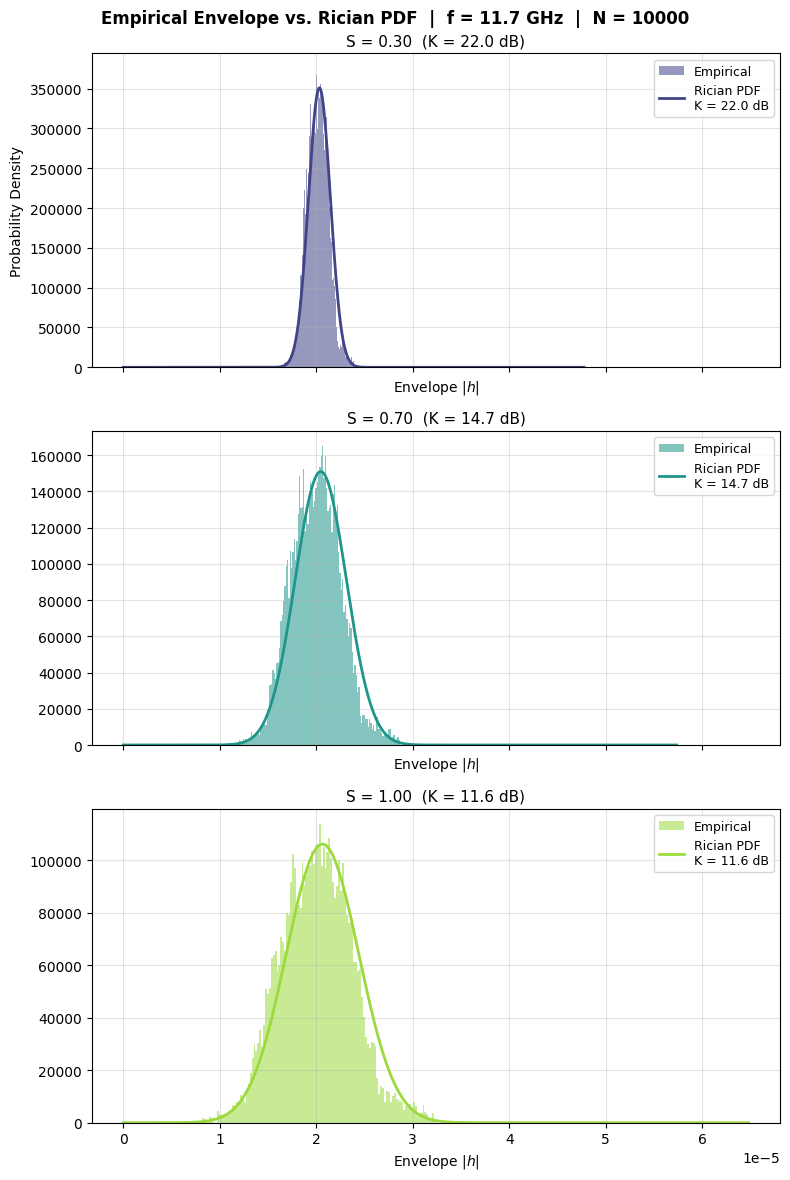

Saved rician_pdf_comparison.png


In [14]:
fig, axes = plt.subplots(
    ncols=1, nrows=len(S_VALUES),
    figsize=(8, 4 * len(S_VALUES)),
    sharey=False,
    sharex=True
)
if len(S_VALUES) == 1:
    axes = [axes]

colors   = plt.cm.viridis(np.linspace(0.2, 0.85, len(S_VALUES)))
num_bins = int(np.sqrt(15000))

for i, s in enumerate(S_VALUES):
    ax   = axes[i]
    H    = np.array(H_[i])
    K    = Ks[i]
    Omg  = Omegas[i]

    x_plt = np.linspace(0, 2 * np.max(H) + 1e-30, 10_000)

    ax.hist(H, bins=num_bins, density=True,
            alpha=0.55, color=colors[i], edgecolor="none", label="Empirical")
    ax.plot(x_plt, rician_pdf(x_plt, K, Omg),
            color=colors[i], lw=2.0,
            label=f"Rician PDF\nK = {10*np.log10(K+1e-12):.1f} dB")

    ax.set_title(f"S = {s:.2f}  (K = {10*np.log10(K+1e-12):.1f} dB)", fontsize=11)
    ax.set_xlabel(r"Envelope $|h|$")
    ax.set_ylabel("Probability Density" if i == 0 else "")
    ax.legend(fontsize=9)
    ax.grid(True, alpha=0.35)

fig.suptitle(
    f"Empirical Envelope vs. Rician PDF  |  f = {FREQUENCY/1e9:.1f} GHz  |  "
    f"N = {N_REALIZATIONS}",
    fontsize=12, fontweight="bold"
)
# plt.xlim(1.8e-5, 2.2e-5)
plt.tight_layout()
plt.savefig("rician_pdf_comparison.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved rician_pdf_comparison.png")

## 10 · Example CIRs per Scattering Parameter

Plots one representative CIR for each S value using stored raw data.
LoS paths are shown in red; scattered/diffracted paths in blue.

In [21]:
results1 = sims["raw_results"]
results2 = sims2["raw_results"]

print(results1[0][0].keys())

dict_keys(['taus', 'amps', 'inter_d0', 'vert_d0', 'obj_d0'])


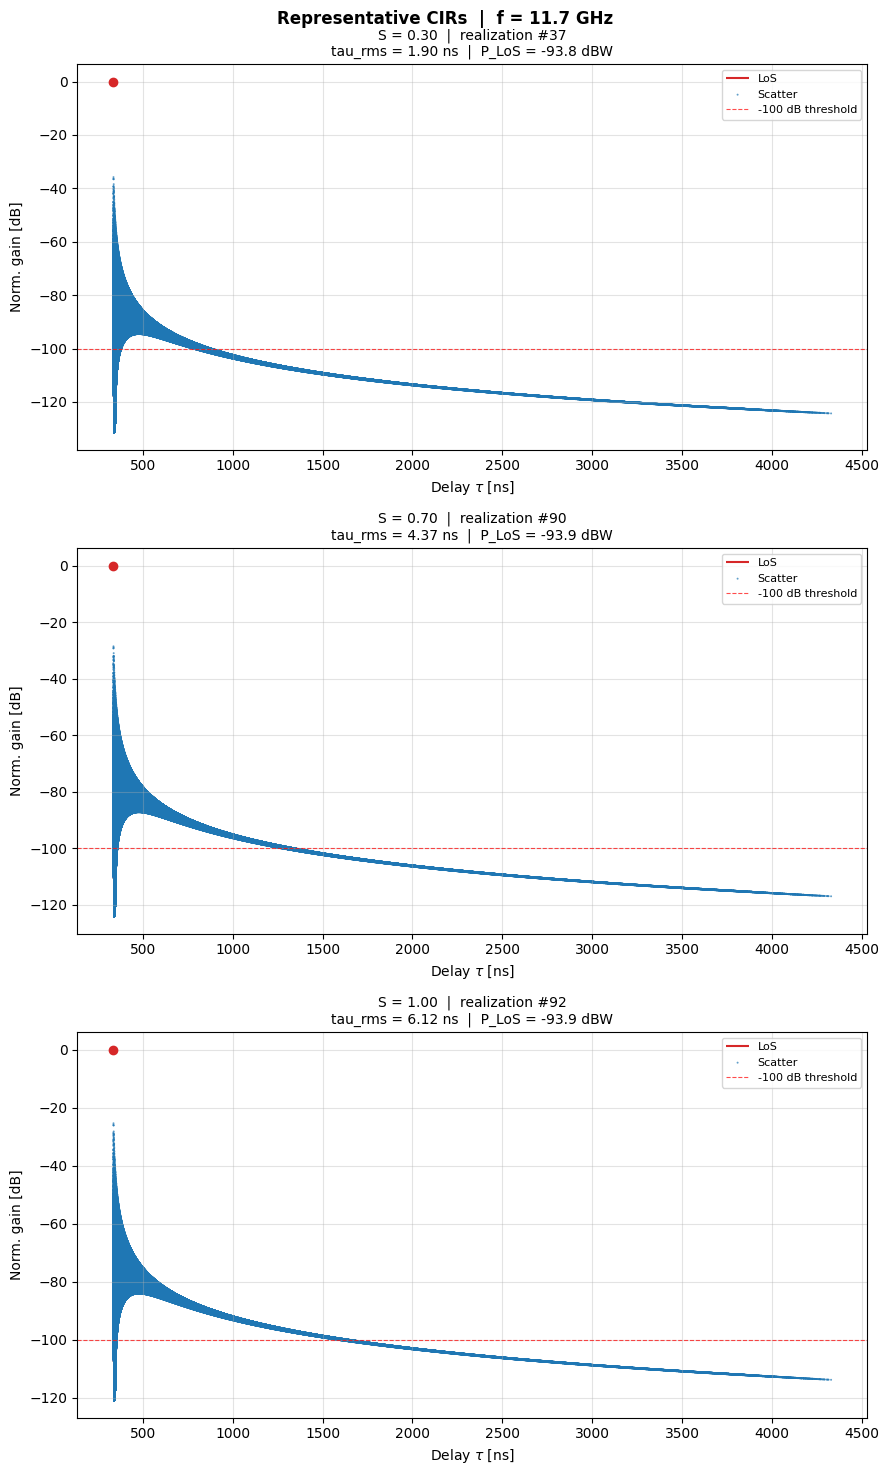

Saved example_cirs.png


In [32]:
def plot_cir(ax, taus, amps, inter_d0, title="", normalise=True):
    """
    Stem-plot CIR from raw path data.

    Parameters
    ----------
    top_n     : keep only the strongest top_n paths (by amplitude) for clarity
    normalise : normalise gain relative to the strongest path [dB]
    """
    t = np.asarray(taus)
    a = np.asarray(amps)
    d = np.asarray(inter_d0)

    # # Keep top-N by power
    # if len(a) > top_n:
    #     idx  = np.argsort(np.abs(a))[-top_n:]
    #     t, a, d = t[idx], a[idx], d[idx]

    a_dB = 20 * np.log10(np.abs(a) + 1e-30)
    if normalise:
        a_dB -= np.max(a_dB)

    los_mask  = (d == 0)
    scat_mask = ~los_mask

    if np.any(los_mask):
        ml, sl, _ = ax.stem(t[los_mask]  * 1e9, a_dB[los_mask],
                            linefmt="C3-", markerfmt="C3o", basefmt=" ")
        plt.setp(ml, markersize=6)
        plt.setp(sl, linewidth=1.5, label="LoS")

    if np.any(scat_mask):
        ax.scatter(t[scat_mask] * 1e9, a_dB[scat_mask], label="Scatter", color="C0", alpha=0.7, edgecolor="none", s=2)
        # plt.setp(ms, markersize=3)
        # plt.setp(ss, linewidth=0.8, alpha=0.6, label="Scatter")
    
    # threshold horizontal line at - 100 dB
    ax.axhline(-100, color="red", linestyle="--", linewidth=0.8, alpha=0.7, label="-100 dB threshold")

    ax.set_xlabel(r"Delay $\tau$ [ns]")
    ax.set_ylabel("Norm. gain [dB]" if normalise else "Path gain [dB]")
    ax.set_title(title, fontsize=10)
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.35)


# ── One representative CIR per S: realisation with highest LoS power ──────────
fig, axes = plt.subplots(len(S_VALUES), 1, figsize=(9, 5 * len(S_VALUES),))
if len(S_VALUES) == 1:
    axes = [axes]

for i, s in enumerate(S_VALUES):
    # Select realisation with highest LoS power
    # best_idx = int(np.argmax([p[i] for p in P_[i]]))
    rand_idx = np.random.randint(len(results1[i]))
    r        = results1[i][rand_idx]
    _, tau_r = rms_delay_spread(r["taus"], r["amps"])
    P_los_dB = 10 * np.log10(P_[i][rand_idx][0] + 1e-30)

    plot_cir(
        axes[i], r["taus"], r["amps"], r["inter_d0"],
        title=(f"S = {s:.2f}  |  realization #{rand_idx}\n"
               f"tau_rms = {tau_r*1e9:.2f} ns  |  "
               f"P_LoS = {P_los_dB:.1f} dBW"), normalise=True
    )

fig.suptitle(
    f"Representative CIRs  |  f = {FREQUENCY/1e9:.1f} GHz",
    fontsize=12, fontweight="bold"
)
plt.tight_layout()
plt.savefig("example_cirs.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved example_cirs.png")

## 12 · Custom CIR Picker

Change `S_IDX` and `REAL_IDX` to inspect any specific realisation.
No re-simulation needed — uses stored raw data.

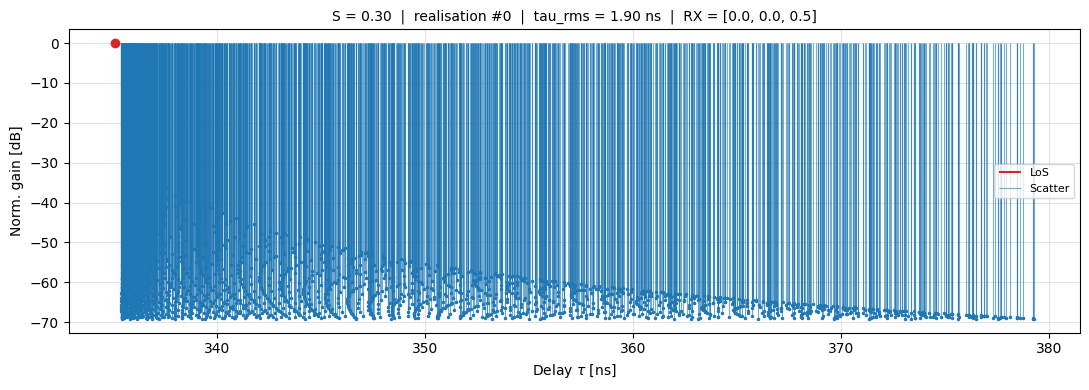

In [28]:
S_IDX    = 0    # index into S_VALUES  (0 -> S=0.3,  1 -> S=0.7,  2 -> S=1.0)
REAL_IDX = 0   # realisation index within that S value


fig, ax = plt.subplots(figsize=(11, 4))

r = raw_results[S_IDX][REAL_IDX]
_, tau_rms_pick = rms_delay_spread(r["taus"], r["amps"])
plot_cir(
    ax, r["taus"], r["amps"], r["inter_d0"],
    title=(f"S = {S_VALUES[S_IDX]:.2f}  |  realisation #{REAL_IDX}  |  "
            f"tau_rms = {tau_rms_pick*1e9:.2f} ns  |  RX = {RX_NOM}"),
    top_n=2000, normalise=True
)
plt.tight_layout()
plt.show()

# Scattered Path Validation

In [ ]:
# Borrowed from Sionna report
from scipy.constants import epsilon_0

def calculate_path_distance(tx_pos, rx_pos, points, objects):
    """
    returns distance for path, number of bounces
    """
    # Calculate distances between consecutive vertices
    segment_distances = []
    total_distance = 0.0
    depth = 0
    
    total_points = []
    total_points.append(tx_pos)
    
    i = 0
    while i < points.shape[0] and not all(np.isclose([0.0, 0.0, 0.0], points[i])):
        # drop invalid points(negative z, or bad objects)
        if points[i, 2] >= 0 and objects[i] != 4294967295 :
            total_points.append(points[i])
        
        i += 1
    total_points.append(rx_pos)
    # print(total_points)
    total_points = np.asarray(total_points)
        
    for j in range(len(total_points) - 1):
        segment_dist = np.linalg.norm(total_points[j+1, :] - total_points[j, :])
        segment_distances.append(segment_dist)
        total_distance += segment_dist
        depth += 1

    # print("Total path distance:", total_distance)    
    depth = depth - 1
    return total_distance, depth
# Calculate angle between two vectors
def angle_between_vectors(v1, v2):
    """Calculate the angle in degrees between two vectors."""
    v1_u = v1 / np.linalg.norm(v1)
    v2_u = v2 / np.linalg.norm(v2)
    dot_product = np.clip(np.dot(v1_u, v2_u), -1.0, 1.0)
    # print("Dot product:", dot_product)
    angle_rad = np.arccos(dot_product)
    # print("Angle in radians:", angle_rad)
    angle_deg = np.degrees(angle_rad)
    # print("Angle in degrees:", angle_deg)
    return angle_deg

# Calculate Fresnel reflection coefficient
def fresnel_reflection_coefficient(epsilon_r, sigma, fc, epsilon_0, incident_angle_deg):
    """Calculate the Fresnel reflection coefficient for perpendicular polarization."""
    
    epsilon_c = epsilon_r - 1j * sigma / (2 * np.pi * fc * epsilon_0)
#     print("Hand Complex permittivity:", epsilon_c)
    incident_angle_rad = np.radians(incident_angle_deg)

    Z = np.sqrt(epsilon_c-np.cos(incident_angle_rad)**2)
    R_parallel = (epsilon_c*np.sin(incident_angle_rad) - Z) / (epsilon_c*np.sin(incident_angle_rad) + Z)
    R_perpendicular = (np.sin(incident_angle_rad) - Z) / (np.sin(incident_angle_rad) + Z)
    # R = np.sqrt((np.abs(R_parallel)**2 + np.abs(R_perpendicular)**2) / 2)

    return R_perpendicular, R_parallel

# Convert reflection coefficient to normalized reflection loss in dB
def normalized_reflection_loss(G_t, G_r, R, d, fc):
    """Convert reflection coefficient to normalized reflection loss in dB."""

    c = 3e8  # Speed of light in m/s
    wavelength = c / fc
    RL = (G_t * G_r * (np.abs(R)**2)  * wavelength**2) / ((4 * np.pi * d)**2)
    RL_dB = -10 * np.log10(RL)
    
    return RL_dB

def normalized_scattered_reflection_loss(
    G_t, G_r, R_par, R_perp, fc,
    tx_pos, ground_bounce_point, rx_pos,
    beam_angle, n_rays=1_000_000
):
    """
    Compute diffuse-scatter path power gain using the full Jones matrix
    polarisation formulation for a ground-bounce event.

    The TX->scatter leg distance (d1) cancels exactly with the illuminated
    area element, so only d2 (scatter->RX) appears in the Friis factor.

    Parameters
    ----------
    G_t, G_r            : TX / RX antenna gains (linear)
    R_par               : Fresnel TM (p / parallel) reflection coefficient (complex)
    R_perp              : Fresnel TE (s / perpendicular) reflection coefficient (complex)
    fc                  : carrier frequency (Hz)
    tx_pos              : (3,) transmitter position (m)
    ground_bounce_point : (3,) scatter point on ground (m)
    rx_pos              : (3,) receiver position (m)
    beam_angle          : half-cone angle of TX beam (rad); set to
                          np.arccos(1 - 2/(4*np.pi / delta_omega_iso))
                          for isotropic, or np.arctan(scene_radius / d1)
                          for cone beamforming
    n_rays              : number of rays in the launch (sets ΔΩ = Ω_cone / n_rays)

    Returns
    -------
    RL_dB   : path loss in dB (positive = loss)
    """
    s = 0.3          # scattering parameter
    c = 3e8
    wavelength = c / fc

    tx = np.asarray(tx_pos,              dtype=float).ravel()
    bp = np.asarray(ground_bounce_point, dtype=float).ravel()
    rx = np.asarray(rx_pos,              dtype=float).ravel()

    # ── Surface normal: upward for ground bounce ─────────────────────────────
    n_hat = np.array([0., 0., 1.])

    # ── Ray directions ───────────────────────────────────────────────────────
    inc_vec  = bp - tx      # TX  →  scatter point
    scat_vec = rx - bp      # scatter point  →  RX

    d1 = np.linalg.norm(inc_vec)
    d2 = np.linalg.norm(scat_vec)

    k_i = inc_vec  / d1     # unit incident direction  (toward surface)
    k_s = scat_vec / d2     # unit scattered direction (away from surface)

    # ── TE / TM polarisation frames ──────────────────────────────────────────
    def te_tm_frame(k_hat, n_hat):
        """
        Returns (s_hat, p_hat) — the TE and TM basis vectors for a ray with
        direction k_hat at a surface with outward normal n_hat.

          s_hat : TE  — perpendicular to the plane of incidence (= k × n̂)
          p_hat : TM  — in the plane of incidence, perpendicular to k_hat
                        (= s_hat × k_hat, so (s, p, k) is right-handed)
        """
        cross = np.cross(k_hat, n_hat)
        norm  = np.linalg.norm(cross)

        s_hat = cross / norm
        p_hat = np.cross(s_hat, k_hat)   # TM: in plane of incidence, ⊥ to k
        return s_hat, p_hat

    s_i, p_i = te_tm_frame(k_i, n_hat)   # incident  TE/TM frame
    s_s, p_s = te_tm_frame(k_s, n_hat)   # scattered TE/TM frame

    # ── Change-of-basis matrix M ─────────────────────────────────────────────
    # Rotates from the incident TE/TM frame into the scattered TE/TM frame.
    # Each entry is the dot product of the corresponding basis vectors:
    #
    #   M = | s_s·s_i   s_s·p_i |
    #       | p_s·s_i   p_s·p_i |
    #
    M = np.array([
        [np.dot(s_s, s_i), np.dot(s_s, p_i)],
        [np.dot(p_s, s_i), np.dot(p_s, p_i)]
    ])  # (2, 2) real

    
    # Unpolarised: average TE and TM contributions weighted by row norms of M.
    # Equivalent to averaging over all input polarisations and summing outputs.
    #   = (|Γ_⊥|² · ||row1(M)||² + |Γ_∥|² · ||row2(M)||²) / 2
    row1_norm_sq = np.dot(M[0], M[0])   # ||ŝ_s projected onto incident frame||²
    row2_norm_sq = np.dot(M[1], M[1])   # ||p̂_s projected onto incident frame||²

    gamma_eff_sq = (np.abs(R_perp)**2 * row1_norm_sq + np.abs(R_par)**2 * row2_norm_sq)/2


    # ── Lambertian angular factor ─────────────────────────────────────────────
    # cos θ_s : angle between the scattered ray and the surface normal.
    cos_theta_s = np.abs(np.dot(k_s, n_hat))

    # ── Per-ray solid angle ───────────────────────────────────────────────────
    # Total solid angle of the launch cone divided by number of rays.
    omega_cone  = 2 * np.pi * (1 - np.cos(beam_angle))
    delta_omega = omega_cone / n_rays

    # ── Diffuse sampling probability ──────────────────────────────────────────
    p_diff = 1

    power_gain = (
        G_t * G_r
        * (1.0 / p_diff)
        * delta_omega
        * s**2
        * gamma_eff_sq
        * (cos_theta_s / np.pi)
        * (wavelength / (4.0 * np.pi * d2))**2
    )

    RL_dB = 10.0 * np.log10(power_gain)
    return RL_dB


In [47]:
print(epsilon_0)
print(FREQUENCY)

8.8541878188e-12
11700000000.0


In [69]:
r = raw_results[S_IDX][REAL_IDX]
time = r["taus"]
amplitudes = r["amps"]
inter_d0 = r["inter_d0"]
verts = r["vert_d0"]
obj = r["obj_d0"]

# print(verts.shape)
# print(obj.shape)

los_mask  = (inter_d0 == 0)
scat_mask = np.where(~los_mask)[0]



print("Number of scattered paths:", len(scat_mask))

id = [5, 25, 1000]

rand_scat_idx = scat_mask[id]

for idx in rand_scat_idx:
    print("Randomly selected scatter path index:", idx)
    print("Path Amplitude:", 20 * np.log10(np.abs(amplitudes[idx]) + 1e-30), "dB")


    # Compute a few expected values for scattered paths 
    bounce_point = np.array(verts[idx][:])
    dist = np.linalg.norm(TX_POS - bounce_point) + np.linalg.norm(RX_NOM - bounce_point)  # excess path length over LoS
    source_tx = np.squeeze(TX_POS)
    incident_vec_p1 = source_tx - bounce_point

    incident_angle = angle_between_vectors(incident_vec_p1, [0,0,1])


    epsilon_r_plane = eta_r
    conductivity_plane = sigma
    g = 1.0
    # omega = 2 * np.pi * FREQUENCY

    # fresnel_reflection_coefficient
    R_perp, R_par = fresnel_reflection_coefficient(epsilon_r_plane, conductivity_plane, FREQUENCY, epsilon_0, 90-incident_angle)
    
    RL_dB = normalized_scattered_reflection_loss(g, g, R_perp, R_par, FREQUENCY, ground_bounce_point=bounce_point, rx_pos=RX_NOM,tx_pos=TX_POS, beam_angle=BEAM_ANGLE, n_rays=1_000_000)
    print(f"Estimated loss for this path: {RL_dB:.2f} dB")


Number of scattered paths: 606173
Randomly selected scatter path index: 5
Path Amplitude: -200.8457417657181 dB
Estimated loss for this path: -190.64 dB
Randomly selected scatter path index: 25
Path Amplitude: -219.18171851334333 dB
Estimated loss for this path: -194.65 dB
Randomly selected scatter path index: 1000
Path Amplitude: -215.7181663163725 dB
Estimated loss for this path: -194.06 dB


## 13 · CIR Grid — Multiple Realisations for One S Value

Useful for visualising how the CIR varies within a single S sweep.

In [ ]:
S_IDX_GRID = 1          # which S value to plot
N_GRID     = 6          # number of realisations to show (arranged in 2 rows)

fig, axes = plt.subplots(2, N_GRID // 2, figsize=(7 * (N_GRID // 2), 8))
axes_flat = axes.flatten()

# Spread evenly across realisations
indices = np.linspace(0, len(raw_results[S_IDX_GRID]) - 1, N_GRID, dtype=int)

for col, real_idx in enumerate(indices):
    r = results[S_IDX_GRID][real_idx]
    _, tau_r = rms_delay_spread(r["taus"], r["amps"])
    plot_cir(
        axes_flat[col], r["taus"], r["amps"], r["inter_d0"],
        title=f"Real. #{real_idx}  tau_rms={tau_r*1e9:.1f} ns",
        top_n=600, normalise=True
    )

fig.suptitle(
    f"CIR grid  |  S = {S_VALUES[S_IDX_GRID]:.2f}  |  "
    f"f = {FREQUENCY/1e9:.1f} GHz  |  N = {N_GRID} samples",
    fontsize=12, fontweight="bold"
)
plt.tight_layout()
plt.savefig(f"cir_grid_S{S_VALUES[S_IDX_GRID]:.2f}.png", dpi=150, bbox_inches="tight")
plt.show()

## 14 · Optional: Scene Preview

In [ ]:
scene_vis, _ = build_scene(RX_NOM, TX_POS, s_value=S_VALUES[0])

paths_vis = solver(
    scene=scene_vis,
    max_depth=1,
    los=True,
    specular_reflection=False,
    diffuse_reflection=True,
    refraction=False,
    diffraction=False,
    synthetic_array=False,
    max_num_paths_per_src=200,
    samples_per_src=10_000,
    seed=drjit.cuda.ad.UInt(1),
    beamforming=True,
    beam_angle=BEAM_ANGLE
)

bird_cam = Camera(position=[-150, -150, 200], look_at=RX_NOM)
scene_vis.render_to_file(
    camera=bird_cam,
    filename="rician_testbench_preview.png",
    paths=paths_vis
)
print("Saved rician_testbench_preview.png")